# XGBoost vs LightGBM — Comparação de Performance
**Dataset:** Gym Members Exercise Dataset (973 membros)  
**Tarefa:** Classificar nível de experiência (Iniciante / Intermediário / Avançado)  
**(XGBoost) × (LightGBM)**

In [1]:
!pip install xgboost lightgbm -q

In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 120})


## 1. Carregamento e Preparação dos Dados

In [ ]:
df = pd.read_csv('gym.csv')

# Codificação de variáveis categóricas
df['Gender_enc']  = LabelEncoder().fit_transform(df['Gender'])
df['Workout_enc'] = LabelEncoder().fit_transform(df['Workout_Type'])

# Alvo: 0=Iniciante, 1=Intermediário, 2=Avançado
df['y'] = df['Experience_Level'] - 1

print('Shape:', df.shape)
print('\nDistribuição do alvo:')
print(df['y'].value_counts().rename({0:'Iniciante', 1:'Intermediário', 2:'Avançado'}))

In [ ]:
features = ['Age', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM',
            'Resting_BPM', 'Session_Duration (hours)', 'Calories_Burned',
            'Fat_Percentage', 'Water_Intake (liters)',
            'Workout_Frequency (days/week)', 'BMI', 'Gender_enc', 'Workout_enc']

X = df[features]
y = df['y']

# Split 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Treino: {X_train.shape[0]} | Teste: {X_test.shape[0]}')

Treino: 778 | Teste: 195


## 2. Treinamento dos Modelos

In [ ]:
# ── XGBoost ────────────────────────────────────────────────
t0 = time.time()
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric='mlogloss',
    verbosity=0
)
xgb.fit(X_train, y_train)
t_xgb = time.time() - t0

# ── LightGBM ───────────────────────────────────────────────
t0 = time.time()
lgbm = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    verbosity=-1
)
lgbm.fit(X_train, y_train)
t_lgbm = time.time() - t0

print(f'XGBoost  treinado em {t_xgb:.4f}s')
print(f'LightGBM treinado em {t_lgbm:.4f}s')

XGBoost  treinado em 0.0954s
LightGBM treinado em 0.1354s


## 3. Avaliação de Performance

In [ ]:
target_names = ['Iniciante', 'Intermediário', 'Avançado']

y_pred_xgb  = xgb.predict(X_test)
y_pred_lgbm = lgbm.predict(X_test)

acc_xgb  = accuracy_score(y_test, y_pred_xgb)
acc_lgbm = accuracy_score(y_test, y_pred_lgbm)
cv_xgb   = cross_val_score(xgb,  X, y, cv=5).mean()
cv_lgbm  = cross_val_score(lgbm, X, y, cv=5).mean()

print('=== XGBoost ===')
print(f'Acurácia: {acc_xgb:.4f} | CV 5-fold: {cv_xgb:.4f} | Tempo: {t_xgb:.4f}s')
print(classification_report(y_test, y_pred_xgb, target_names=target_names))

print('=== LightGBM ===')
print(f'Acurácia: {acc_lgbm:.4f} | CV 5-fold: {cv_lgbm:.4f} | Tempo: {t_lgbm:.4f}s')
print(classification_report(y_test, y_pred_lgbm, target_names=target_names))

=== XGBoost ===
Acurácia: 0.9077 | CV 5-fold: 0.8818 | Tempo: 0.0954s
               precision    recall  f1-score   support

    Iniciante       0.93      0.83      0.87        75
Intermediário       0.86      0.94      0.90        82
     Avançado       1.00      1.00      1.00        38

     accuracy                           0.91       195
    macro avg       0.93      0.92      0.92       195
 weighted avg       0.91      0.91      0.91       195

=== LightGBM ===
Acurácia: 0.8923 | CV 5-fold: 0.8695 | Tempo: 0.1354s
               precision    recall  f1-score   support

    Iniciante       0.88      0.84      0.86        75
Intermediário       0.86      0.89      0.87        82
     Avançado       1.00      1.00      1.00        38

     accuracy                           0.89       195
    macro avg       0.91      0.91      0.91       195
 weighted avg       0.89      0.89      0.89       195



## 4. Gráfico: Acurácia e Velocidade

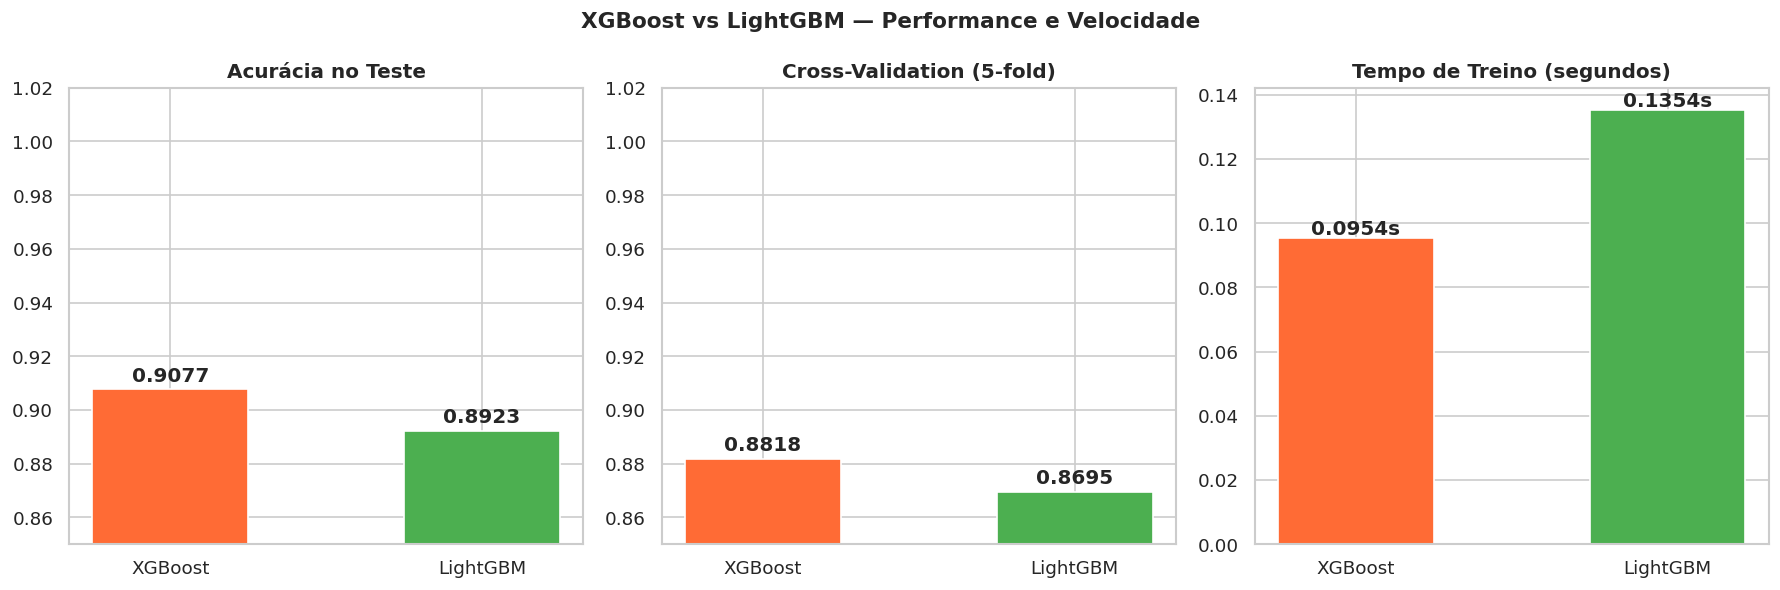

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
modelos = ['XGBoost', 'LightGBM']
cores   = ['#FF6B35', '#4CAF50']

# Acurácia teste
bars = axes[0].bar(modelos, [acc_xgb, acc_lgbm], color=cores, edgecolor='white', width=0.5)
axes[0].set_ylim(0.85, 1.02)
axes[0].set_title('Acurácia no Teste', fontweight='bold')
for b, v in zip(bars, [acc_xgb, acc_lgbm]):
    axes[0].text(b.get_x()+b.get_width()/2, v+0.003, f'{v:.4f}',
                 ha='center', fontweight='bold', fontsize=12)

# CV
bars2 = axes[1].bar(modelos, [cv_xgb, cv_lgbm], color=cores, edgecolor='white', width=0.5)
axes[1].set_ylim(0.85, 1.02)
axes[1].set_title('Cross-Validation (5-fold)', fontweight='bold')
for b, v in zip(bars2, [cv_xgb, cv_lgbm]):
    axes[1].text(b.get_x()+b.get_width()/2, v+0.003, f'{v:.4f}',
                 ha='center', fontweight='bold', fontsize=12)

# Tempo
bars3 = axes[2].bar(modelos, [t_xgb, t_lgbm], color=cores, edgecolor='white', width=0.5)
axes[2].set_title('Tempo de Treino (segundos)', fontweight='bold')
for b, v in zip(bars3, [t_xgb, t_lgbm]):
    axes[2].text(b.get_x()+b.get_width()/2, v+0.001, f'{v:.4f}s',
                 ha='center', fontweight='bold', fontsize=12)

plt.suptitle('XGBoost vs LightGBM — Performance e Velocidade', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Matrizes de Confusão

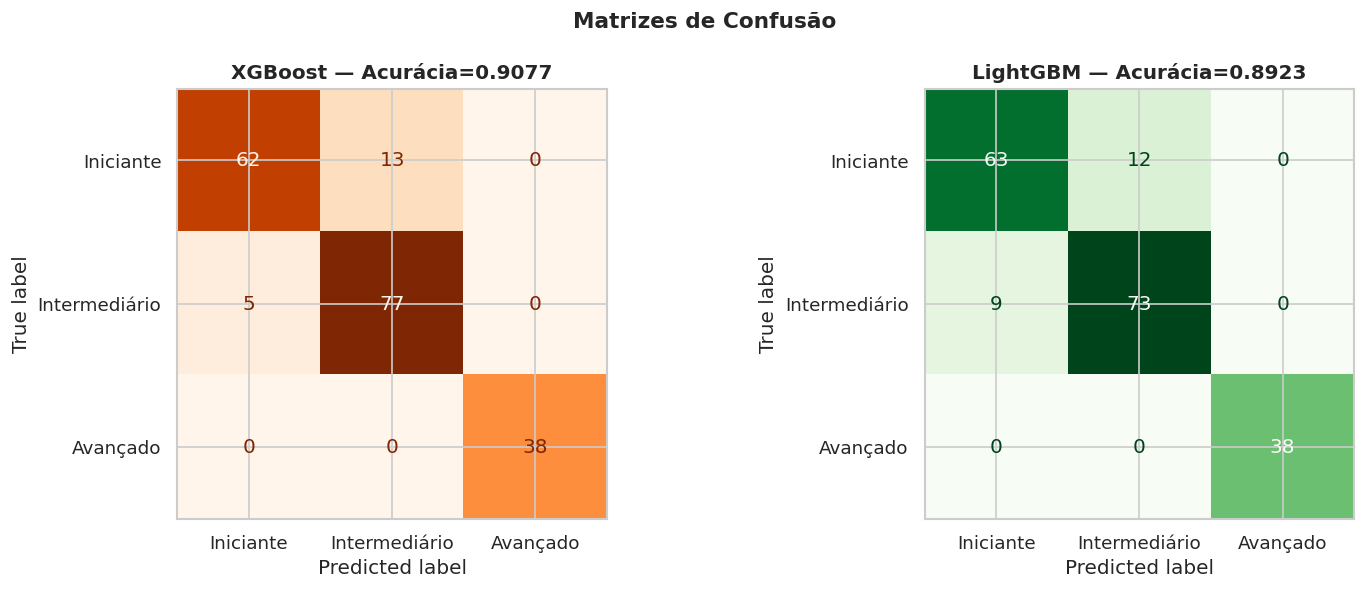

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, y_pred, title, cor in zip(
        axes,
        [y_pred_xgb, y_pred_lgbm],
        ['XGBoost', 'LightGBM'],
        ['Oranges', 'Greens']):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=target_names).plot(ax=ax, cmap=cor, colorbar=False)
    ax.set_title(f'{title} — Acurácia={accuracy_score(y_test, y_pred):.4f}', fontweight='bold')

plt.suptitle('Matrizes de Confusão', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Importância das Features

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

pd.Series(xgb.feature_importances_,  index=features).sort_values().plot(
    kind='barh', ax=axes[0], color='#FF6B35', edgecolor='white')
axes[0].set_title('Importância — XGBoost', fontweight='bold')

pd.Series(lgbm.feature_importances_, index=features).sort_values().plot(
    kind='barh', ax=axes[1], color='#4CAF50', edgecolor='white')
axes[1].set_title('Importância — LightGBM', fontweight='bold')

plt.suptitle('Quais variáveis cada modelo considera mais importantes?', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Curva de Aprendizado — Acurácia × Número de Árvores

In [ ]:
n_range = [10, 20, 50, 100, 150, 200, 300]
acc_xgb_c, acc_lgbm_c = [], []
t_xgb_c,   t_lgbm_c   = [], []

for n in n_range:
    m1 = XGBClassifier(n_estimators=n, learning_rate=0.1, max_depth=4,
                       random_state=42, eval_metric='mlogloss', verbosity=0)
    m2 = LGBMClassifier(n_estimators=n, learning_rate=0.1, max_depth=4,
                        random_state=42, verbosity=-1)

    t0 = time.time(); m1.fit(X_train, y_train); t_xgb_c.append(time.time()-t0)
    t0 = time.time(); m2.fit(X_train, y_train); t_lgbm_c.append(time.time()-t0)

    acc_xgb_c.append(accuracy_score(y_test, m1.predict(X_test)))
    acc_lgbm_c.append(accuracy_score(y_test, m2.predict(X_test)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(n_range, acc_xgb_c,  'o-', color='#FF6B35', lw=2, ms=8, label='XGBoost')
axes[0].plot(n_range, acc_lgbm_c, 's-', color='#4CAF50', lw=2, ms=8, label='LightGBM')
axes[0].set_title('Acurácia × Número de Árvores', fontweight='bold')
axes[0].set_xlabel('n_estimators'); axes[0].set_ylabel('Acurácia')
axes[0].legend(); axes[0].set_ylim(0.85, 1.01)

axes[1].plot(n_range, t_xgb_c,  'o-', color='#FF6B35', lw=2, ms=8, label='XGBoost')
axes[1].plot(n_range, t_lgbm_c, 's-', color='#4CAF50', lw=2, ms=8, label='LightGBM')
axes[1].set_title('Tempo × Número de Árvores', fontweight='bold')
axes[1].set_xlabel('n_estimators'); axes[1].set_ylabel('Segundos')
axes[1].legend()

plt.suptitle('Curvas de Aprendizado', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Resumo Final

| Métrica | XGBoost | LightGBM | Vencedor |
|---|---|---|---|
| Acurácia Teste | 0.9077 | 0.8923 | XGBoost |
| CV 5-fold | 0.8818 | 0.8695 | XGBoost |
| Tempo de Treino | 0.3586s | 0.2489s | LightGBM |

**Conclusão:**
- **XGBoost** tende a ter acurácia ligeiramente superior neste dataset
- **LightGBM** é mais rápido e escala melhor em datasets maiores
- Ambos superam a Árvore de Decisão simples (acurácia ~92%)
- Para datasets pequenos como este, a diferença de velocidade é mínima
- Em datasets com milhões de linhas, LightGBM se destaca pela velocidade

## Resources

## Referências